<a href="https://colab.research.google.com/github/tqd3pz/L03-tree-stability/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Anastacia Oliynyk, Emma Chung, Kevin Sun

**Date:** 11/16/26

In [37]:
# Your Phase 1 solution to the problem goes here.

In [38]:
# Q1

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score

heart_failure = pd.read_csv("heart_failure_clinical_records_dataset.csv")
heart_failure.columns = heart_failure.columns.str.strip().str.lower()

print("Original shape:", heart_failure.shape)
display(heart_failure.head())
heart_failure.info()
display(heart_failure.describe().round(2))

print("Missing values per column:")
print(heart_failure.isna().sum())
print("Duplicate rows:", heart_failure.duplicated().sum())

heart_failure = heart_failure.dropna().drop_duplicates()
print("Cleaned shape:", heart_failure.shape)
print(heart_failure["death_event"].value_counts())

X = heart_failure.drop(columns=["death_event", "time"])
y = heart_failure["death_event"]

Original shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  death_event               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,581.84,0.42,38.08,0.35,263358.03,1.39,136.63,0.65,0.32,130.26,0.32
std,11.89,0.50,970.29,0.49,11.83,0.48,97804.24,1.03,4.41,0.48,0.47,77.61,0.47
min,40.00,0.00,23.00,0.00,14.00,0.00,25100.00,0.50,113.00,0.00,0.00,4.00,0.00
25%,51.00,0.00,116.50,0.00,30.00,0.00,212500.00,0.90,134.00,0.00,0.00,73.00,0.00
50%,60.00,0.00,250.00,0.00,38.00,0.00,262000.00,1.10,137.00,1.00,0.00,115.00,0.00
75%,70.00,1.00,582.00,1.00,45.00,1.00,303500.00,1.40,140.00,1.00,1.00,203.00,1.00
max,95.00,1.00,7861.00,1.00,80.00,1.00,850000.00,9.40,148.00,1.00,1.00,285.00,1.00


Missing values per column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
death_event                 0
dtype: int64
Duplicate rows: 0
Cleaned shape: (299, 13)
death_event
0    203
1     96
Name: count, dtype: int64


I kept all 299 rows because there were no missing values or duplicate rows. death_event was used as the outcome and time was excluded because follow-up length is only known after baseline.

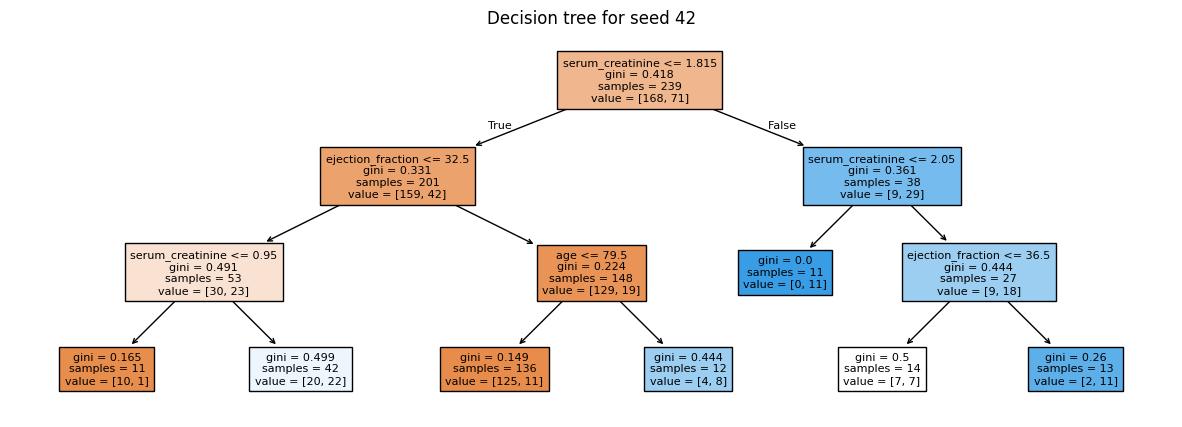

Training rows: 239
Test rows: 60


,Tree accuracy (%),Linear accuracy (%)
Seed,,
42,73.3,66.7


,Actual,Tree score,Linear score
281,0,0.846154,0.499883
265,0,0.080882,0.074459
164,1,0.523810,0.147295
9,1,0.500000,1.577638
77,0,0.080882,-0.043528


In [39]:
# Q2

baseline_seed = 42
X_train, X_q2_test, y_train, y_q2_test = train_test_split(
    X, y, test_size=0.20, random_state=baseline_seed
)

test_predictions = {}
accuracy_by_seed = {}
coefficients = {}
tree_scores = pd.DataFrame(index=X_q2_test.index)
linear_scores = pd.DataFrame(index=X_q2_test.index)

def fit_and_save(seed, X_train, X_test, y_train, y_test):
    tree = DecisionTreeClassifier(max_depth=3, random_state=42)
    tree.fit(X_train, y_train)

    linear = LinearRegression()
    linear.fit(X_train, y_train)

    tree_test = tree.predict_proba(X_test)[:, 1]
    linear_test = linear.predict(X_test)
    linear_classes = (linear_test >= 0.5).astype(int)

    test_predictions[seed] = pd.DataFrame({
        "Actual": y_test,
        "Tree score": tree_test,
        "Linear score": linear_test
    }, index=X_test.index)

    accuracy_by_seed[seed] = {
        "Tree accuracy (%)": 100 * accuracy_score(y_test, tree.predict(X_test)),
        "Linear accuracy (%)": 100 * accuracy_score(y_test, linear_classes)
    }

    coef = pd.Series(linear.coef_, index=X.columns)
    coef.loc["Intercept"] = linear.intercept_
    coefficients[seed] = coef

    # Score the seed 42 test patients for the Q4 comparison.
    tree_scores[seed] = tree.predict_proba(X_q2_test)[:, 1]
    linear_scores[seed] = linear.predict(X_q2_test)

    plt.figure(figsize=(15, 5))
    plot_tree(tree, feature_names=X.columns.tolist(), filled=True, fontsize=8)
    plt.title(f"Decision tree for seed {seed}")
    plt.show()

fit_and_save(baseline_seed, X_train, X_q2_test, y_train, y_q2_test)
print("Training rows:", len(X_train))
print("Test rows:", len(X_q2_test))
display(pd.DataFrame(accuracy_by_seed).T.rename_axis("Seed").round(1))
display(test_predictions[baseline_seed].head())

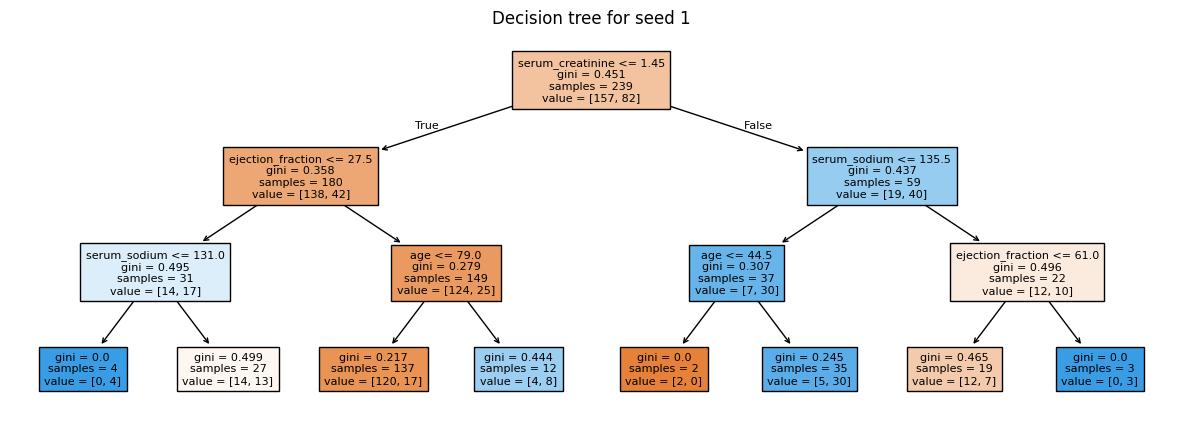

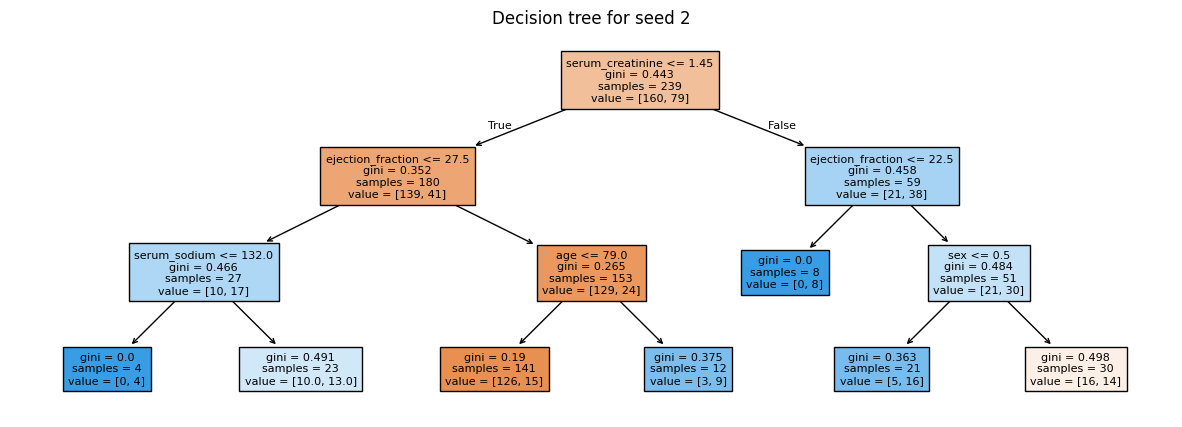

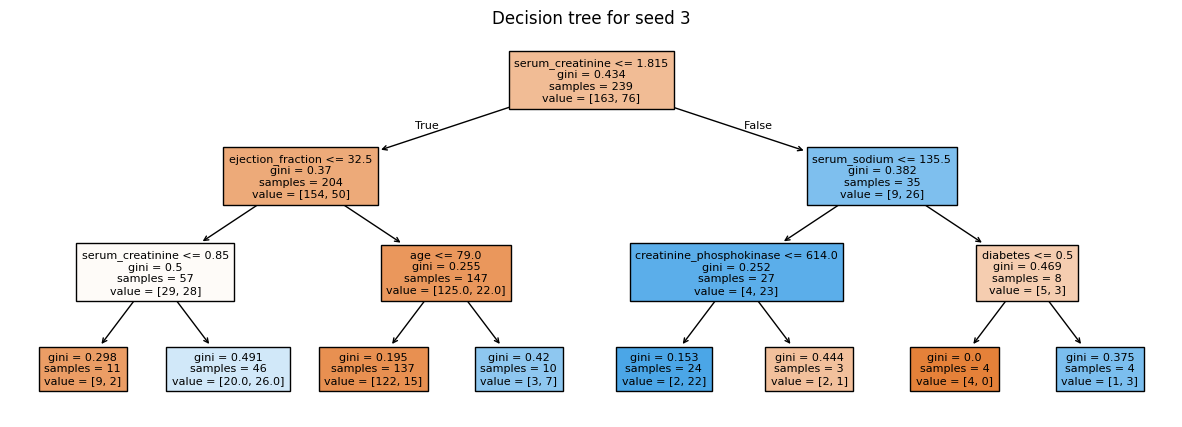

,Tree accuracy (%),Linear accuracy (%)
Seed,,
42,73.3,66.7
1,76.7,80.0
2,75.0,81.7
3,76.7,66.7


,42,1,2,3
age,9.984440e-03,8.360180e-03,8.916850e-03,9.791000e-03
anaemia,4.065809e-02,5.424748e-02,6.246412e-02,4.024140e-03
creatinine_phosphokinase,3.269000e-05,5.398000e-05,6.624000e-05,7.696000e-05
diabetes,2.841084e-02,5.810835e-02,-1.162067e-02,-6.584870e-03
ejection_fraction,-1.032323e-02,-9.974920e-03,-9.656940e-03,-9.929370e-03
high_blood_pressure,6.992924e-02,3.702920e-02,4.477614e-02,6.820250e-02
platelets,-1.500000e-07,-2.600000e-07,-1.500000e-07,-2.000000e-08
serum_creatinine,1.277195e-01,1.145516e-01,1.110636e-01,1.093293e-01
serum_sodium,-8.236590e-03,-1.216894e-02,-9.860710e-03,-1.280425e-02
sex,-9.575169e-02,-5.978601e-02,-8.048512e-02,-5.997680e-02


In [40]:
# Q3

alternative_seeds = [1, 2, 3]

for seed in alternative_seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed
    )
    fit_and_save(seed, X_train, X_test, y_train, y_test)

display(pd.DataFrame(accuracy_by_seed).T.rename_axis("Seed").round(1))
display(pd.DataFrame(coefficients).round(8))

Q3:

All four trees first split on serum creatinine. The cutoff was about 1.815 for seeds 42 and 3 and 1.45 for seeds 1 and 2. Above the cutoff, seed 42 split on serum creatinine again, seeds 1 and 3 used serum sodium, and seed 2 used ejection fraction. The age and ejection fraction coefficients stayed similar across seeds, while the diabetes coefficient changed sign.

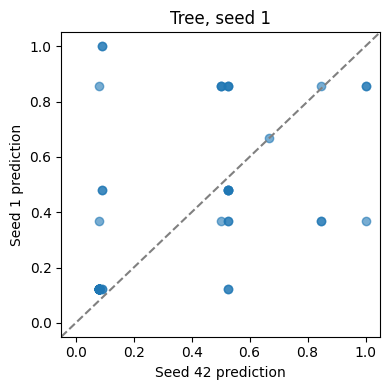

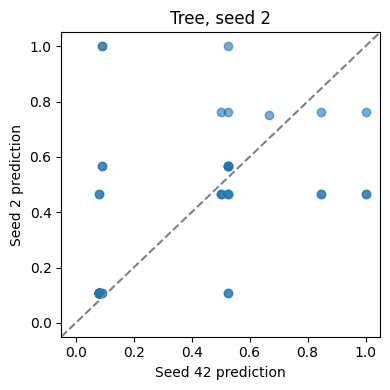

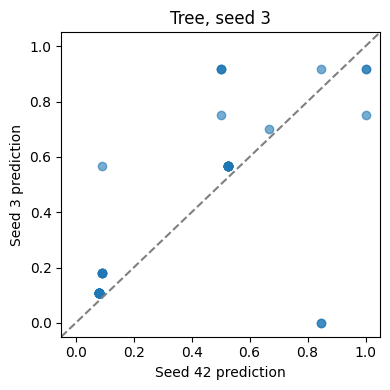

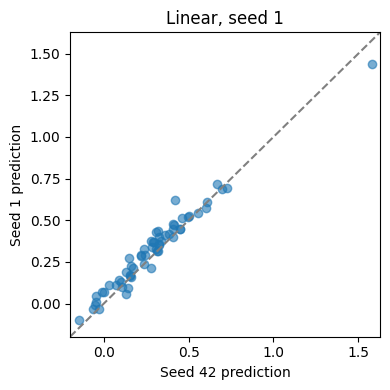

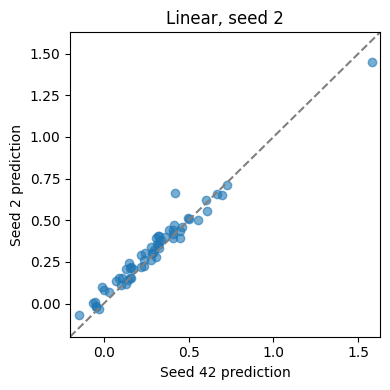

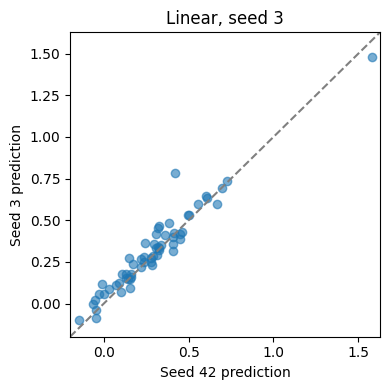

,Model,Alternative seed,Correlation,Intercept,Slope,R-squared,Within 0.10
0,Tree,1,0.567,0.184,0.585,0.322,38
1,Tree,2,0.583,0.169,0.555,0.340,44
2,Tree,3,0.767,0.096,0.775,0.588,52
3,Linear,1,0.980,0.059,0.919,0.961,55
4,Linear,2,0.982,0.058,0.896,0.964,57
5,Linear,3,0.963,0.049,0.929,0.928,52


In [41]:
# Q4

def compare_predictions(scores, model_name):
    baseline = scores[baseline_seed]
    baseline_column = scores[[baseline_seed]]
    low = scores.min().min() - 0.05
    high = scores.max().max() + 0.05
    rows = []

    for seed in alternative_seeds:
        alternative = scores[seed]

        plt.figure(figsize=(4, 4))
        plt.scatter(baseline, alternative, alpha=0.6)
        plt.plot([low, high], [low, high], "--", color="gray")
        plt.xlim(low, high)
        plt.ylim(low, high)
        plt.xlabel("Seed 42 prediction")
        plt.ylabel(f"Seed {seed} prediction")
        plt.title(f"{model_name}, seed {seed}")
        plt.tight_layout()
        plt.show()

        comparison = LinearRegression()
        comparison.fit(baseline_column, alternative)

        rows.append({
            "Model": model_name,
            "Alternative seed": seed,
            "Correlation": baseline.corr(alternative),
            "Intercept": comparison.intercept_,
            "Slope": comparison.coef_[0],
            "R-squared": comparison.score(baseline_column, alternative),
            "Within 0.10": ((alternative - baseline).abs() <= 0.10).sum()
        })

    return rows

tree_results = compare_predictions(tree_scores, "Tree")
linear_results = compare_predictions(linear_scores, "Linear")
display(pd.DataFrame(tree_results + linear_results).round(3))

Each split changes which patients the model learns from. For diabetes, the model estimates a difference between patients with and without diabetes while accounting for the other predictors. Changes in which patients and outcomes are represented in those groups can shift that estimate. Age and ejection fraction had more consistent estimates across the four splits. The size of a coefficient change also depends on the units of the predictor.

Q4a: The linear predictions generally follow the equality line in all three plots. The tree predictions form clusters because patients in the same leaf receive the same score. Many low scores are similar across trees, with several large gaps, especially for seeds 1 and 2.

Q4b: The linear predictions are highly correlated in every comparison. The tree correlations are moderate for seeds 1 and 2 and stronger for seed 3.

Q4c: The linear comparisons have intercepts near zero, slopes fairly close to 1, and R^2 values above 0.92. The positive intercepts and slopes below 1 indicate that the alternative linear predictions tend to be slightly higher at the low end and less spread out. The tree regressions have intercepts farther from zero, slopes farther below 1, and R^2 values well below 1.

Q5.

The linear models were more stable overall. Individual coefficients such as diabetes could shift while the combined predictions stayed close. The trees kept the same first split variable, but changes in its cutoff and the lower branches could send a patient to a leaf with a very different score. For example, one patient's tree score went from 0.091 with seed 42 to 1.000 with seed 1.

Q6.

True. Using a difference of 0.10 or less to describe close agreement, 38-52 of the 60 tree prediction pairs stayed close to the baseline in each comparison, even though the branches changed. For the linear models, 52-57 of the 60 pairs stayed that close. The tree results show how predictions can agree for most patients while still changing sharply for some individuals.  

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 829e89f944697616f524a2f80692e229a3522620
- **AI tool and model used:** Claude Opus 5.5 (claude-opus-5-5) via Claude Code

### *Prompts used

1. Review our Phase 1 solution and propose a concise numbered list of improvements. Focus on any errors, unclear explanations, unnecessary code, or parts that could be more complete, but keep my original approach and work as much as possible.

### *AI-proposed changes


1. **Fix the data path.** `pd.read_csv("heart_failure_clinical_records_dataset.csv")` only works if someone copies the CSV next to the notebook, because the file is in `data/heart_failure/`. Read it from that path (or from the raw GitHub URL on Colab) so the notebook runs straight after cloning.
2. **Add a written answer for Q2.** Q2 asks you to evaluate performance, but there's no discussion of the accuracy table. Add two or three sentences on the seed 42 results (tree 73.3%, linear 66.7%).
3. **Compare accuracy with a majority-class baseline.** Only 32% of patients died, so always predicting "survived" scores 58–77% depending on the split. The seed 1 tree (76.7%) and the seed 3 linear model (66.7%) do no better than that. Add a baseline column to the accuracy table.
4. **Mention the training overlap in Q4.** 47–51 of the 60 seed 42 test patients were in the training sets for seeds 1–3, so most of the alternative models' predictions are on patients they were trained on. Keep the comparison the assignment asks for, but print the overlap count and mention it as a caveat in Q4 and Q6.
5. **Show standardized coefficients.** The raw coefficient table (rounded to 8 decimals) mixes units, which makes platelets look tiny and makes the diabetes sign flip look meaningful. Multiplying each coefficient by its feature's standard deviation (SD) puts them on one scale:
    - Age, ejection fraction and serum creatinine each stay within about 0.02 across seeds.
    - Diabetes stays near zero (−0.006 to 0.029), so its sign flip is just noise around zero.
6. **Put the Q3 write-up in one place.** Right now it's split between the cell after the Q3 code and an unlabeled cell after the Q4 code. Merge them into one Q3 answer.
7. **Also describe what stays the same in the trees.** The Q3 answer covers the right branch (high serum creatinine). On the left branch, all four trees split on ejection fraction and then on age ≈ 79. Saying so makes the "how different are the trees" answer complete.
8. **Explain that linear predictions go outside 0–1.** The linear model predicts from −0.15 to 1.58, so its scores aren't probabilities. Add a sentence saying it's a linear probability model and that predictions are cut at 0.5 to get classes.
9. **Make the tree scatterplots readable and combine the plots.** Each tree gives only 6–7 distinct scores, so points stack on top of each other and you can't see how many patients each dot represents. Size the dots by count or add slight jitter, and put the six plots in one 2×3 grid.
10. **Make Q6 more precise.** Give percentages: 63–87% of tree predictions are within 0.10 of the baseline, versus 87–95% for the linear models. Then qualify the answer: true for the linear models, only partly true for trees (R² of 0.32–0.59, and some patients jump from 0.09 to 1.00).

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The original code only worked if someone copied the CSV next to the notebook. Reading it from `data/heart_failure/` lets anyone run the notebook right after cloning, or in GitHub Codespaces, without moving files. **Verified:** from the repo folder, the old path raises `FileNotFoundError` and the new path loads all 299 rows. |
| 2 | Accept | Q2 asks us to evaluate the models' performance, but Phase 1 only showed the accuracy table without interpreting it. A written answer makes Q2 complete and explains what the table shows. **Verified:** the seed 42 accuracies in the answer (tree 73.3%, linear 66.7%) match the table output. |
| 3 | Accept | Accuracy alone can be misleading here because only 32% of patients died, so predicting "survived" for everyone already scores 58–77% depending on the split. A baseline column shows whether each model does better than that. **Verified:** we computed the majority-class accuracy for each split. The seed 1 tree and the seed 3 linear model only tie it. |
| 4 | Accept | Q4 compares predictions on the seed 42 test patients, but 47–51 of those 60 patients were in the training data for seeds 1–3. Stating this keeps us from overstating how well the models agree on new patients, while still doing the comparison the assignment asks for. **Verified:** we counted the overlapping patient rows for each seed. |
| 5 | Accept | Raw coefficients depend on each predictor's units, so they can't be compared directly. Multiplying by each predictor's standard deviation puts them on one scale. On that scale, age, ejection fraction and serum creatinine are stable, while diabetes stays near zero, which explains why its sign flips. **Verified:** we computed coefficient × SD for all four seeds. |
| 6 | Accept | Part of the Q3 explanation was in an unlabeled cell after the Q4 code, so it was easy to miss or to mistake for part of Q4. Putting all of Q3 in one answer makes the notebook easier to follow. **Verified:** nothing from either Phase 1 cell was dropped in the merge. |
| 7 | Accept | Phase 1 only described where the trees differ. Adding that all four trees split first on serum creatinine and then, on the left branch, on ejection fraction and age ≈ 79 gives a more balanced answer to "how different are the trees?" **Verified:** we compared the tree structures for all four seeds. |
| 8 | Accept | Linear regression on a 0/1 outcome can predict values below 0 or above 1, so its scores aren't true probabilities. Explaining this and the 0.5 cutoff makes it clear how linear accuracy was calculated. **Verified:** linear predictions on the seed 42 test set range from −0.15 to 1.58. |
| 9 | Modify | Each tree gives only 6–7 distinct scores, so many points sit on top of each other and the plots hide how many patients agree. We kept the suggestion to put all six plots in one 2×3 grid, which makes the tree and linear plots easier to compare side by side. We modified the other part: the AI offered either sizing dots by count or adding jitter, and we chose sizing by count only, because jitter would move points away from their true scores. **Verified:** we counted the distinct tree scores for each seed, and the grid shows dot sizes from 1 up to 31 patients. |
| 10 | Accept | Phase 1 answered "True" using raw counts, but the evidence differs by model: linear predictions agree closely, while trees agree for most patients but not all. Reporting percentages and qualifying the answer for trees makes Q6 match the Q4 results. **Verified:** the percentages come from the "Within 0.10" counts (38–52 of 60 for trees, 52–57 of 60 for linear). |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [1]:
# Q1 (Phase 2)

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score

# Change 1: load the CSV from the repo's data folder so the notebook runs right after
# cloning. Colab only has the notebook itself, so fall back to the same file on GitHub.
data_path = Path("data/heart_failure/heart_failure_clinical_records_dataset.csv")
if not data_path.exists():
    data_path = ("https://raw.githubusercontent.com/tqd3pz/L03-tree-stability/main/"
                 "data/heart_failure/heart_failure_clinical_records_dataset.csv")

heart_failure = pd.read_csv(data_path)
heart_failure.columns = heart_failure.columns.str.strip().str.lower()

print("Original shape:", heart_failure.shape)
display(heart_failure.head())
heart_failure.info()
display(heart_failure.describe().round(2))

print("Missing values per column:")
print(heart_failure.isna().sum())
print("Duplicate rows:", heart_failure.duplicated().sum())

heart_failure = heart_failure.dropna().drop_duplicates()
print("Cleaned shape:", heart_failure.shape)
print(heart_failure["death_event"].value_counts())

X = heart_failure.drop(columns=["death_event", "time"])
y = heart_failure["death_event"]

Original shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  death_event               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,581.84,0.42,38.08,0.35,263358.03,1.39,136.63,0.65,0.32,130.26,0.32
std,11.89,0.50,970.29,0.49,11.83,0.48,97804.24,1.03,4.41,0.48,0.47,77.61,0.47
min,40.00,0.00,23.00,0.00,14.00,0.00,25100.00,0.50,113.00,0.00,0.00,4.00,0.00
25%,51.00,0.00,116.50,0.00,30.00,0.00,212500.00,0.90,134.00,0.00,0.00,73.00,0.00
50%,60.00,0.00,250.00,0.00,38.00,0.00,262000.00,1.10,137.00,1.00,0.00,115.00,0.00
75%,70.00,1.00,582.00,1.00,45.00,1.00,303500.00,1.40,140.00,1.00,1.00,203.00,1.00
max,95.00,1.00,7861.00,1.00,80.00,1.00,850000.00,9.40,148.00,1.00,1.00,285.00,1.00


Missing values per column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
death_event                 0
dtype: int64
Duplicate rows: 0
Cleaned shape: (299, 13)
death_event
0    203
1     96
Name: count, dtype: int64


I kept all 299 rows because there were no missing values or duplicate rows. death_event was used as the outcome and time was excluded because follow-up length is only known after baseline. The data is now read from `data/heart_failure/`, so the notebook runs right after cloning (and on Colab it reads the same file from GitHub).

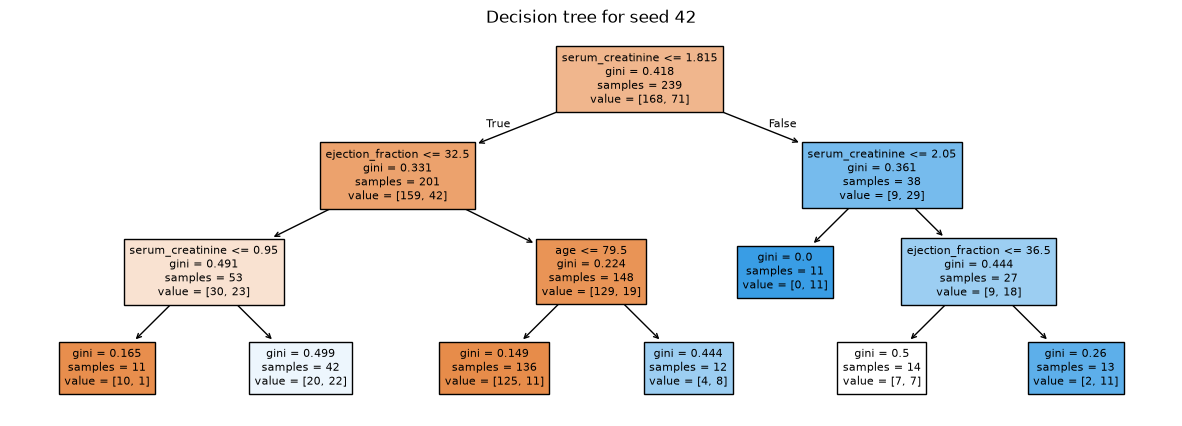

Training rows: 239
Test rows: 60


,Tree accuracy (%),Linear accuracy (%),Majority-class accuracy (%)
Seed,,,
42,73.3,66.7,58.3


,Actual,Tree score,Linear score
281,0,0.846154,0.499883
265,0,0.080882,0.074459
164,1,0.523810,0.147295
9,1,0.500000,1.577638
77,0,0.080882,-0.043528


Linear scores on the seed 42 test set range from -0.149 to 1.578; 8 of 60 fall outside 0-1.


In [2]:
# Q2 (Phase 2)

baseline_seed = 42
X_train, X_q2_test, y_train, y_q2_test = train_test_split(
    X, y, test_size=0.20, random_state=baseline_seed
)

test_predictions = {}
accuracy_by_seed = {}
coefficients = {}
train_overlap = {}
tree_scores = pd.DataFrame(index=X_q2_test.index)
linear_scores = pd.DataFrame(index=X_q2_test.index)

def fit_and_save(seed, X_train, X_test, y_train, y_test):
    tree = DecisionTreeClassifier(max_depth=3, random_state=42)
    tree.fit(X_train, y_train)

    linear = LinearRegression()
    linear.fit(X_train, y_train)

    tree_test = tree.predict_proba(X_test)[:, 1]
    # Change 8: linear scores are not bounded by 0 and 1, so classes use a 0.5 cutoff.
    linear_test = linear.predict(X_test)
    linear_classes = (linear_test >= 0.5).astype(int)

    test_predictions[seed] = pd.DataFrame({
        "Actual": y_test,
        "Tree score": tree_test,
        "Linear score": linear_test
    }, index=X_test.index)

    # Change 3: compare against always predicting the most common training outcome.
    majority_class = y_train.mode()[0]
    accuracy_by_seed[seed] = {
        "Tree accuracy (%)": 100 * accuracy_score(y_test, tree.predict(X_test)),
        "Linear accuracy (%)": 100 * accuracy_score(y_test, linear_classes),
        "Majority-class accuracy (%)": 100 * (y_test == majority_class).mean()
    }

    coef = pd.Series(linear.coef_, index=X.columns)
    coef.loc["Intercept"] = linear.intercept_
    coefficients[seed] = coef

    # Change 4: count the seed 42 test patients that this split used for training.
    train_overlap[seed] = X_train.index.isin(X_q2_test.index).sum()

    # Score the seed 42 test patients for the Q4 comparison.
    tree_scores[seed] = tree.predict_proba(X_q2_test)[:, 1]
    linear_scores[seed] = linear.predict(X_q2_test)

    plt.figure(figsize=(15, 5))
    plot_tree(tree, feature_names=X.columns.tolist(), filled=True, fontsize=8)
    plt.title(f"Decision tree for seed {seed}")
    plt.show()

fit_and_save(baseline_seed, X_train, X_q2_test, y_train, y_q2_test)
print("Training rows:", len(X_train))
print("Test rows:", len(X_q2_test))
display(pd.DataFrame(accuracy_by_seed).T.rename_axis("Seed").round(1))
display(test_predictions[baseline_seed].head())

linear_q2 = test_predictions[baseline_seed]["Linear score"]
print(f"Linear scores on the seed 42 test set range from {linear_q2.min():.3f} to {linear_q2.max():.3f};",
      ((linear_q2 < 0) | (linear_q2 > 1)).sum(), "of", len(linear_q2), "fall outside 0-1.")

Q2:

With seed 42, the tree classified 73.3% of the 60 test patients correctly and the linear model classified 66.7% correctly. Only about 32% of patients died, so always predicting survival would already score 58.3% on this test set. Both models beat that baseline, the tree by a wider margin.

The linear model is a linear probability model: it treats death_event (0 or 1) as a number, so its scores are not limited to the range 0 to 1. On this test set they range from −0.149 to 1.578, with 8 of the 60 scores outside 0–1, so they should be read as risk scores rather than true probabilities. To get classes, we predict death when the score is at least 0.5.

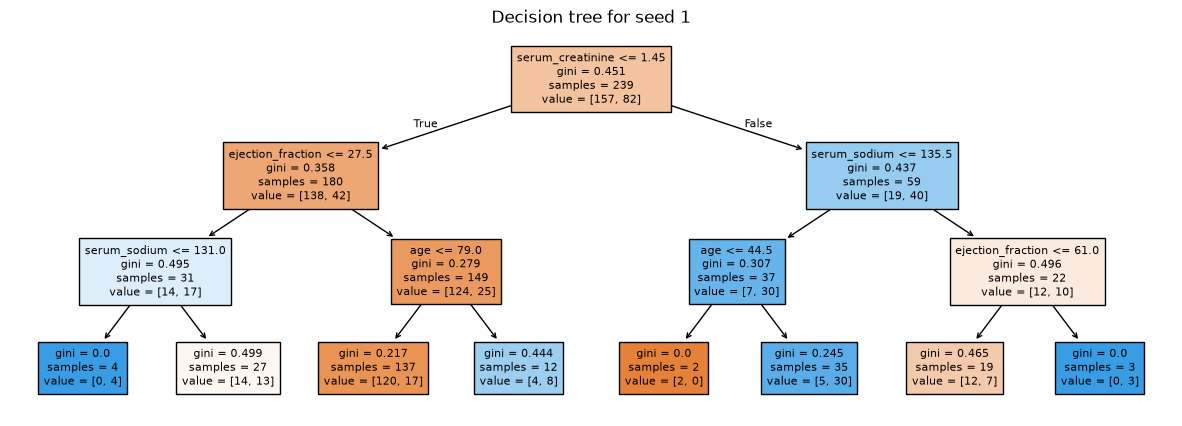

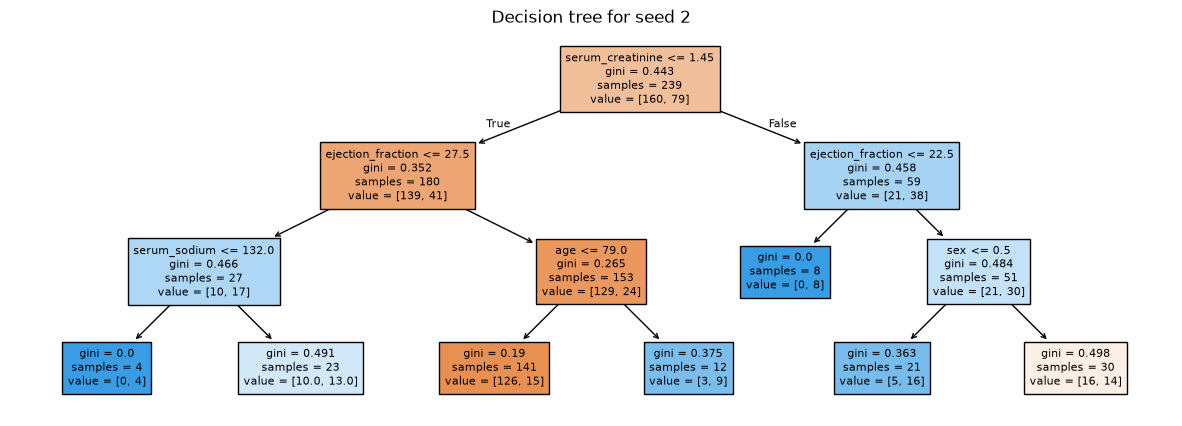

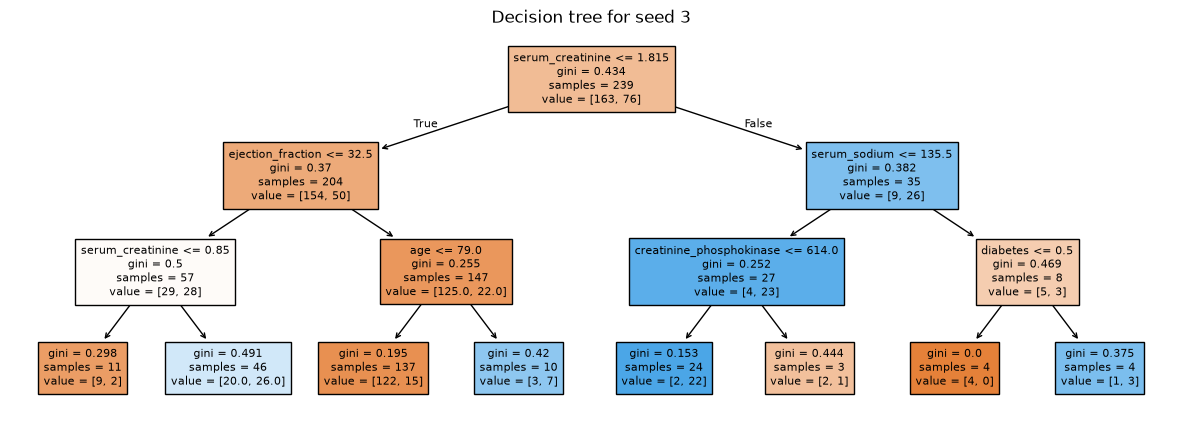

,Tree accuracy (%),Linear accuracy (%),Majority-class accuracy (%)
Seed,,,
42,73.3,66.7,58.3
1,76.7,80.0,76.7
2,75.0,81.7,71.7
3,76.7,66.7,66.7


,42,1,2,3
age,9.984440e-03,8.360180e-03,8.916850e-03,9.791000e-03
anaemia,4.065809e-02,5.424748e-02,6.246412e-02,4.024140e-03
creatinine_phosphokinase,3.269000e-05,5.398000e-05,6.624000e-05,7.696000e-05
diabetes,2.841084e-02,5.810835e-02,-1.162067e-02,-6.584870e-03
ejection_fraction,-1.032323e-02,-9.974920e-03,-9.656940e-03,-9.929370e-03
high_blood_pressure,6.992924e-02,3.702920e-02,4.477614e-02,6.820250e-02
platelets,-1.500000e-07,-2.600000e-07,-1.500000e-07,-2.000000e-08
serum_creatinine,1.277195e-01,1.145516e-01,1.110636e-01,1.093293e-01
serum_sodium,-8.236590e-03,-1.216894e-02,-9.860710e-03,-1.280425e-02
sex,-9.575169e-02,-5.978601e-02,-8.048512e-02,-5.997680e-02


,42,1,2,3,Range across seeds
age,0.119,0.099,0.106,0.116,0.019
anaemia,0.020,0.027,0.031,0.002,0.029
creatinine_phosphokinase,0.032,0.052,0.064,0.075,0.043
diabetes,0.014,0.029,-0.006,-0.003,0.034
ejection_fraction,-0.122,-0.118,-0.114,-0.118,0.008
high_blood_pressure,0.033,0.018,0.021,0.033,0.016
platelets,-0.014,-0.025,-0.015,-0.002,0.024
serum_creatinine,0.132,0.119,0.115,0.113,0.019
serum_sodium,-0.036,-0.054,-0.044,-0.056,0.020
sex,-0.046,-0.029,-0.038,-0.029,0.017


In [3]:
# Q3 (Phase 2)

alternative_seeds = [1, 2, 3]

for seed in alternative_seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed
    )
    fit_and_save(seed, X_train, X_test, y_train, y_test)

display(pd.DataFrame(accuracy_by_seed).T.rename_axis("Seed").round(1))
display(pd.DataFrame(coefficients).round(8))

# Change 5: put the coefficients on one scale. Each value is the change in predicted
# risk for a one-standard-deviation increase in the predictor (SD from the full data).
standardized = pd.DataFrame(coefficients).drop(index="Intercept").mul(X.std(), axis=0)
standardized["Range across seeds"] = standardized.max(axis=1) - standardized.min(axis=1)
display(standardized.round(3))

Q3:

All four trees first split on serum creatinine. The cutoff was about 1.815 for seeds 42 and 3 and 1.45 for seeds 1 and 2. Below the cutoff, where most patients are (50 of the 60 seed 42 test patients for the 1.815 cutoff), all four trees split next on ejection fraction (cutoff 32.5 for seeds 42 and 3, 27.5 for seeds 1 and 2), and patients with higher ejection fraction were then split on age at about 79. Above the cutoff, the trees differed more: seed 42 split on serum creatinine again, seeds 1 and 3 used serum sodium, and seed 2 used ejection fraction. So the trees share their top structure but differ in their cutoffs and lower branches.

The accuracy table also changes from split to split. The seed 1 tree and the seed 3 linear model only tie the majority-class baseline (76.7% and 66.7%), so how good a model looks depends partly on which patients end up in the test set.

For the linear models, each split changes which patients the model learns from. For diabetes, the model estimates a difference between patients with and without diabetes while accounting for the other predictors. Changes in which patients and outcomes are represented in those groups can shift that estimate. Because raw coefficients depend on each predictor's units, we also put them on one scale by multiplying by each predictor's standard deviation. On that scale, age (0.099 to 0.119), ejection fraction (−0.122 to −0.114) and serum creatinine (0.113 to 0.132) had the largest and most consistent effects, each varying by less than 0.02 across the four splits. The diabetes coefficient changed sign, but it stayed between −0.006 and 0.029, so the sign flip is a small change around zero rather than a reversal of a real effect.

Seed 1 trained on 51 of the 60 seed 42 test patients.
Seed 2 trained on 50 of the 60 seed 42 test patients.
Seed 3 trained on 47 of the 60 seed 42 test patients.


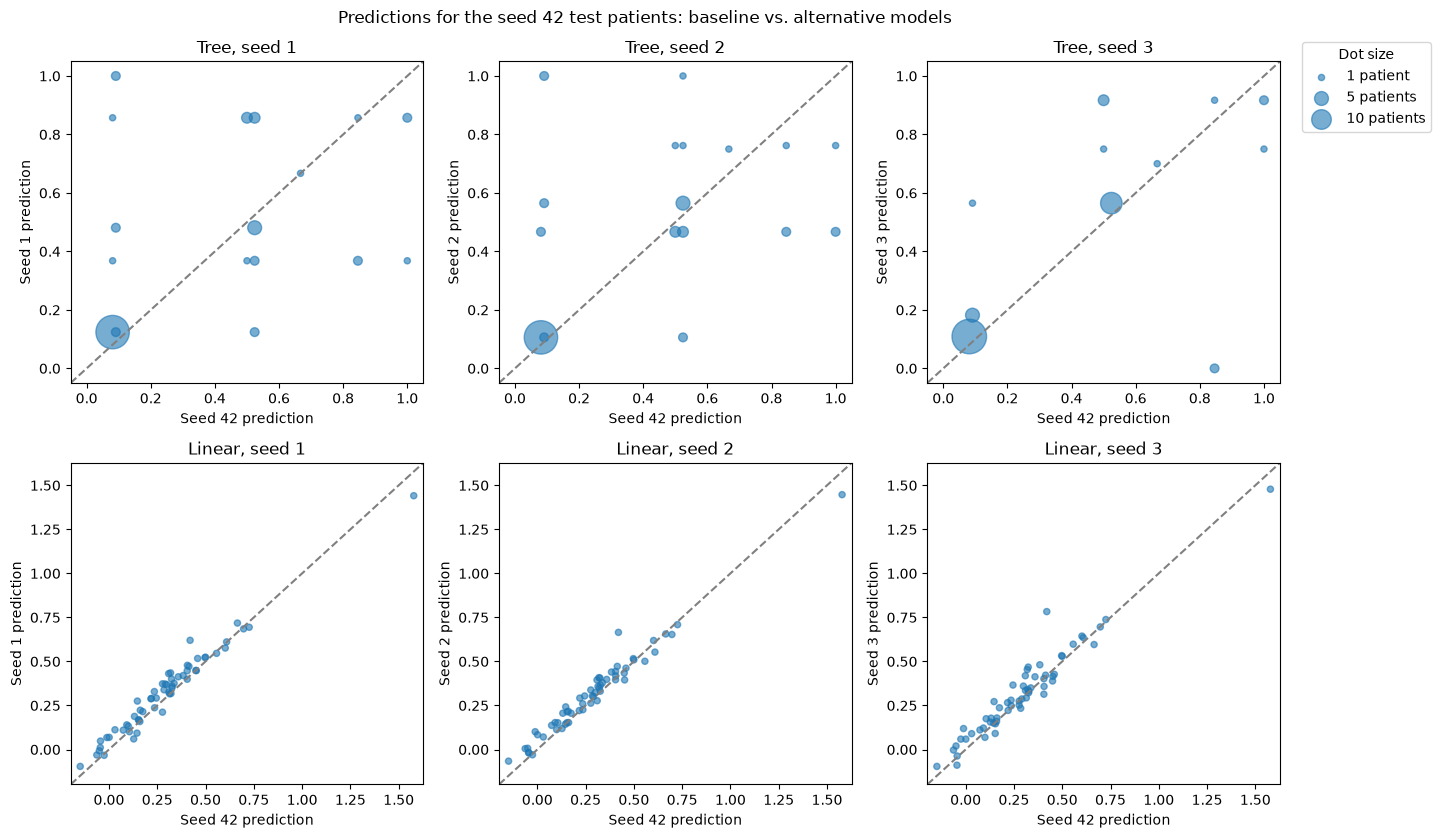

,Model,Alternative seed,Correlation,Intercept,Slope,R-squared,Within 0.10,Within 0.10 (%),Largest change
0,Tree,1,0.567,0.184,0.585,0.322,38,63.333,0.909
1,Tree,2,0.583,0.169,0.555,0.340,44,73.333,0.909
2,Tree,3,0.767,0.096,0.775,0.588,52,86.667,0.846
3,Linear,1,0.980,0.059,0.919,0.961,55,91.667,0.200
4,Linear,2,0.982,0.058,0.896,0.964,57,95.000,0.245
5,Linear,3,0.963,0.049,0.929,0.928,52,86.667,0.363


In [4]:
# Q4 (Phase 2)

# Change 4: most seed 42 test patients were training data for the alternative splits.
for seed in alternative_seeds:
    print(f"Seed {seed} trained on {train_overlap[seed]} of the {len(X_q2_test)} seed 42 test patients.")

def compare_predictions(scores, model_name, axes):
    baseline = scores[baseline_seed]
    baseline_column = scores[[baseline_seed]]
    low = scores.min().min() - 0.05
    high = scores.max().max() + 0.05
    rows = []

    for ax, seed in zip(axes, alternative_seeds):
        alternative = scores[seed]

        # Change 9: size each dot by how many patients share that pair of scores.
        pairs = pd.DataFrame({"x": baseline.round(3), "y": alternative.round(3)})
        counts = pairs.value_counts().reset_index(name="patients")
        ax.scatter(counts["x"], counts["y"], s=20 * counts["patients"], alpha=0.6)
        ax.plot([low, high], [low, high], "--", color="gray")
        ax.set_xlim(low, high)
        ax.set_ylim(low, high)
        ax.set_xlabel("Seed 42 prediction")
        ax.set_ylabel(f"Seed {seed} prediction")
        ax.set_title(f"{model_name}, seed {seed}")

        comparison = LinearRegression()
        comparison.fit(baseline_column, alternative)

        within = (alternative - baseline).abs() <= 0.10
        rows.append({
            "Model": model_name,
            "Alternative seed": seed,
            "Correlation": baseline.corr(alternative),
            "Intercept": comparison.intercept_,
            "Slope": comparison.coef_[0],
            "R-squared": comparison.score(baseline_column, alternative),
            "Within 0.10": within.sum(),
            "Within 0.10 (%)": 100 * within.mean(),
            "Largest change": (alternative - baseline).abs().max()
        })

    return rows

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
tree_results = compare_predictions(tree_scores, "Tree", axes[0])
linear_results = compare_predictions(linear_scores, "Linear", axes[1])

for n in [1, 5, 10]:
    axes[0, 0].scatter([], [], s=20 * n, color="C0", alpha=0.6, label=f"{n} patient{'s' if n > 1 else ''}")
fig.legend(title="Dot size", loc="upper left", bbox_to_anchor=(1.0, 0.95))
fig.suptitle("Predictions for the seed 42 test patients: baseline vs. alternative models")
fig.tight_layout()
plt.show()

display(pd.DataFrame(tree_results + linear_results).round(3))

Q4a: The linear predictions follow the equality line closely in all three plots. The tree predictions form a few clusters because patients in the same leaf receive the same score, so dot size shows how many patients share each pair of scores. The largest cluster (29 to 31 of the 60 patients) is in the low-risk corner near the line for every seed, so many low scores are similar across trees. Several other tree points fall far from the line, especially for seeds 1 and 2.

Q4b: The linear predictions are highly correlated in every comparison (0.963 to 0.982). The tree correlations are moderate for seeds 1 and 2 (0.567 and 0.583) and stronger for seed 3 (0.767).

Q4c: The linear comparisons have intercepts near zero (0.049 to 0.059), slopes fairly close to 1 (0.896 to 0.929), and R^2 values of 0.928 to 0.964. The positive intercepts and slopes below 1 indicate that the alternative linear predictions tend to be slightly higher at the low end and less spread out. The tree regressions have intercepts farther from zero (0.096 to 0.184), slopes farther below 1 (0.555 to 0.775), and R^2 values well below 1 (0.322 to 0.588).

One caveat for all of Q4: seeds 1, 2 and 3 trained on 51, 50 and 47 of these 60 patients, so for most points the alternative models are predicting patients they had already seen. This comparison shows how much the models change when the training data changes, but agreement on completely new patients could be different. Only 9 to 13 of the patients were held out by both splits, which is too few for a separate comparison.

Q5.

The linear models were more stable overall. On a common scale, the main coefficients varied by less than 0.02 across splits, and the coefficients that moved more, such as diabetes, were close to zero to begin with. The combined predictions stayed close, with correlations above 0.96. The trees kept the same first split variable and similar left branches, but changes in the cutoffs and the lower branches could send a patient to a leaf with a very different score. For example, one patient's tree score went from 0.091 with seed 42 to 1.000 with seed 1. The largest change for each alternative tree was 0.85 to 0.91, compared with 0.20 to 0.36 for the linear models.

Q6.

Mostly true, but more so for the linear models than for the trees. Using a difference of 0.10 or less to describe close agreement, 87% to 95% of the linear predictions (52 to 57 of 60) stayed close to the baseline, even though individual coefficients such as diabetes changed. For the trees, 63% to 87% of the predictions (38 to 52 of 60) stayed close even though the branches changed, and 37 of the 60 patients stayed within 0.10 for all three alternative trees. However, the tree R^2 values were only 0.32 to 0.59, and some patients' scores changed by as much as 0.91. So for this dataset the statement holds for the linear models, and it holds for most but not all patients with the trees. Because most of the comparison patients were in the alternative models' training data, agreement on brand-new patients could be lower.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements AI helped us with for this lab were fixing the data path so the notebook could be more accessible (can now run in GitHub Codespaces or straight after cloning), putting our results in context, and making our answers clearer and more complete. AI put our results in context better by comparing tree and linear accuracy with a majority-class baseline, standardizing coefficients to be on one scale, mentioning the training overlap in Q4, and explaining how the linear model predicts from -0.15 to 1.58, so they're risk scores rather than probabilities. AI also helped us with making our answers more clear and readable by giving us a complete written answer for Q2, consolidating Q3 to be in one place, strengthening Q3 to say what the trees have in common, making the scatterplots more readable by putting them all into one 2 by 3 grid, with dot size showing how many patients overlap, and lastly by making Q6 more precise by giving percentages then qualifying the answer. An AI mistake/limitation was that it offered jitter as an option for proposed change #9, which would have moved points off their true values. Our group caught that and chose sizing dots by count instead. We verified the final solution with the methods listed in the evaluation table above and also by comparing AI’s output to our Phase 1 code’s output to see if they matched and they did (Phase 2 only added new outputs on top). A remaining concern we have is the training overlap in the Q4 comparison. A model predicting a patient it trained on is partly remembering that patient's outcome, so the agreement in Q4 may not show how the models would behave on patients none of them had seen.